# Make materials with and without neutronics_material_maker

<!-- index:description -->
Compounds need to be defined before plotting macroscropic cross sections. Compare two ways to create OpenMC materials: defining elemental compositions, enrichment, and densities manually, and using predefined materials from `neutronics_material_maker`.
<!-- /index:description -->

<!-- generated:structure -->
```text
Make materials with and without neutronics_material_maker
├── 1. Without `neutronics_material_maker`
├── 2. With `neutronics_material_maker`
└── 3. Plot macroscopic cross sections
```
<!-- /generated:structure -->


In [1]:
import pandas as pd
import openmc
import neutronics_material_maker as nmm
import matplotlib.pyplot as plt

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

## 1. Without `neutronics_material_maker`
Following a data-science-oriented approach, material compositions are organized in pandas DataFrames, from which OpenMC objects are constructed programmatically. This minimizes repetitive code, reduces the risk of inconsistencies, and makes the model easier to modify and validate.

In [2]:
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
mats_df = pd.DataFrame(columns=[
    'name', 'element', 'percent', 'percent_type',
    'enrichment', 'enrichment_target', 'enrichment_type'
])
mats_df.loc[len(mats_df)] = ['breeder', 'Pb', 84.2, 'ao'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['breeder', 'Li', 15.8, 'ao', 50, 'Li6', 'ao']
mats_df.loc[len(mats_df)] = ['steel', 'Fe', 0.95, 'wo'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['steel', 'C', 0.05, 'wo'] + 3 * [None]
mats_df

,name,element,percent,percent_type,enrichment,enrichment_target,enrichment_type
0,breeder,Pb,84.20,ao,None,None,None
1,breeder,Li,15.80,ao,50,Li6,ao
2,steel,Fe,0.95,wo,None,None,None
3,steel,C,0.05,wo,None,None,None


In [3]:
mats_dic = {}
for name, dat in mats_df.groupby('name'):
    mats_dic[name] = openmc.Material(name=name)

    for _, row in dat.drop(columns='name').iterrows():
        mats_dic[name].add_element(**row.dropna().to_dict())

mats_dic['breeder'].set_density('atom/b-cm', 3.2720171e-2)
mats_dic['steel'].set_density('g/cm3', 7.75)
openmc.Materials(mats_dic.values())

[Material
 	ID             =	1
 	Name           =	breeder
 	Temperature    =	None
 	Density        =	0.032720171 [atom/b-cm]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Pb204          =	1.1788       [ao]
 	Pb206          =	20.2922      [ao]
 	Pb207          =	18.6082      [ao]
 	Pb208          =	44.1208      [ao]
 	Li6            =	7.9          [ao]
 	Li7            =	7.9          [ao],
 Material
 	ID             =	2
 	Name           =	steel
 	Temperature    =	None
 	Density        =	7.75 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Fe54           =	0.053632803115715125 [wo]
 	Fe56           =	0.8730645234058433 [wo]
 	Fe57           =	0.020523501829909044 [wo]
 	Fe58           =	0.002779171648532559 [wo]
 	C12            =	0.04940034225428433 [wo]
 	C13            =	0.0005996577457156737 [wo]]

## 2. With `neutronics_material_maker`

In [4]:
materials = nmm.AvailableMaterials()
list(materials)

['WC',
 'WB',
 'SiC',
 'eurofer',
 'SS_316L_N_IG',
 'tungsten_with_impurities',
 'tungsten',
 'P91',
 'SST91',
 'concrete_ordinary',
 'concrete_heavy',
 'concrete_boronated_heavy',
 'a36_steel',
 'CuCrZr_with_impurities',
 'CuCrZr',
 'Ti-6Al-4V',
 'epoxy_resin',
 'zircaloy_4',
 'Rexolite 1422',
 'ej-200-plastic-scintillator',
 'ej-204-plastic-scintillator',
 'ej-208-plastic-scintillator',
 'ej-212-plastic-scintillator',
 'A-150 Tissue-Equivalent Plastic',
 'Acetone',
 'Acetylene',
 'Air (dry, near sea level)',
 'Alanine',
 'Aluminum',
 'Aluminum Oxide',
 'Aluminum, alloy 2024-O',
 'Aluminum, alloy 2090-T83',
 'Aluminum, alloy 3003',
 'Aluminum, alloy 4043-O',
 'Aluminum, alloy 5086-O',
 'Aluminum, alloy 6061-O',
 'Aluminum, alloy 7075-O',
 'Ammonia (liquid at T= -79 C)',
 'Anthracene',
 'Argon',
 'Asbestos (Chrysotile)',
 'Asphalt',
 'Asphalt pavement',
 'Bakelite',
 'Barium Fluoride',
 'Barium sulfate',
 'Benzene',
 'Beryllium',
 'Beryllium Carbide',
 'Beryllium Oxide',
 'Bismuth',
 '

In [5]:
mats_nmm = {
    'breeder': nmm.Material.from_library(
        name='lithium-lead',
        enrichment=50,
        temperature=573.15,  # 300°C, illustrative
    ).openmc_material,

    'steel': nmm.Material.from_library(
        name='eurofer',
    ).openmc_material,
}
openmc.Materials(mats_nmm.values())

[Material
 	ID             =	4
 	Name           =	lithium-lead
 	Temperature    =	573.15
 	Density        =	9.486504 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Li6            =	0.079        [ao]
 	Li7            =	0.079        [ao]
 	Pb204          =	0.011788     [ao]
 	Pb206          =	0.202922     [ao]
 	Pb207          =	0.186082     [ao]
 	Pb208          =	0.441208     [ao],
 Material
 	ID             =	6
 	Name           =	eurofer
 	Temperature    =	None
 	Density        =	7.78 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Al27           =	4e-05        [ao]
 	B10            =	1.982e-06    [ao]
 	B11            =	8.018e-06    [ao]
 	C12            =	0.0010383680999999998 [ao]
 	C13            =	1.1631899999999998e-05 [ao]
 	Co59           =	5e-05        [ao]
 	Cr50           =	0.0039105    [ao]
 	Cr52           =	0.0754101    [ao]
 	Cr53           =	0.0085509    [ao]
 	

## 3. Plot macroscopic cross sections

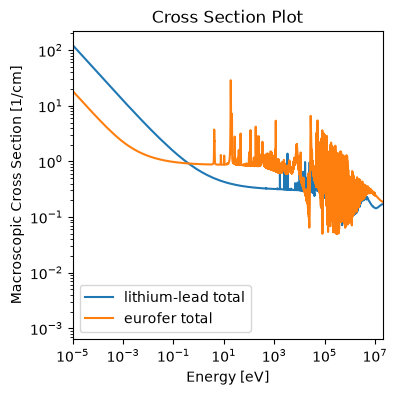

In [6]:
fig, ax = plt.subplots(figsize=(4, 4))
openmc.plot_xs(
    reactions = {
        mat: ['total']
        for mat in mats_nmm.values()
    },
    axis=ax,
)